# StudyMate — Search-model training & evaluation (Colab)
**AI Lab · Project 1E · Course Study Assistant** — Benha University, Faculty of Engineering (Mechatronics, Systems & AI Automation)
Live site: https://ahmedhallawa.pythonanywhere.com · Code: https://github.com/pikachu8240/StudyMate

This notebook **trains and evaluates the four search methods used in the site's "search method" menu**:

| Method | Idea |
|---|---|
| **TF-IDF** | word-weight vectors + cosine similarity (the default) |
| **BM25** | probabilistic ranking with length normalisation (`rank_bm25`) |
| **Hybrid** | 0.5 × TF-IDF + 0.5 × LSA |
| **LSA** | semantic search: TruncatedSVD (100 dims) on the TF-IDF matrix |

It uses the **same code as the website** (`core/search.py`, `core/autoeval.py`), so the percentages here are the percentages the site shows
on its *AI models* page. They change whenever a course is uploaded or rebuilt, because the evaluation is re-run on that course's slides.

**How to use on Colab:** `Runtime ▸ Run all`. To test your own course, run the *Upload your own PDFs* cell and upload lecture PDFs.
At the end, download `results/` (JSON + CSV + charts) — that is the output to give the TA.

## 0 · What the project contains (summary of everything built so far)
**StudyMate** = a Flask web app that answers a student's question *from the course's own slides* (no hallucination: it shows the slide, not a made-up answer).

* **Search & answer:** 4 search methods, "Not found" gate (threshold + coverage), Arabic→English glossary translation, topic classifier (LogReg / Naive Bayes), highlighted slide snippet, confidence, "helpful?" feedback.
* **Students:** register with a code, login, *My courses*, progress/mastery per topic, badges, practice quiz, ready exam, chat, delete-my-account.
* **Study Studio:** Quiz, Mind Map (course name as root), Slide Deck (16:9 PowerPoint-style preview + `.pptx` export), Videos (recorded lectures + YouTube played inside the site), links to Exams / Progress / Materials.
* **Doctors/Admin:** upload lecture PDFs (auto-builds a new course: passages, topics, glossary, question bank, search index), multiple courses, questions follow-up (Open / Answered), dashboard KPIs, FAQ editor, upload recorded lectures / YouTube links.
* **AI-models page** (password-protected): evaluation of the four methods, re-evaluated automatically after every upload/rebuild/retrain.
* **Other:** English/Arabic UI (i18n), light/dark theme (Slate blue palette), Cairo time zone + live clock, Google-Sheets sync, e-mail notifications, 66 automated tests.

In [1]:
# --- Setup: get the project code (the same code that runs the website) ---
import os, sys, subprocess
REPO = "https://github.com/pikachu8240/StudyMate.git"
if not os.path.exists("core/search.py"):                       # running on Colab (or anywhere outside the repo)
    if not os.path.exists("StudyMate"):
        subprocess.run(["git", "clone", "--depth", "1", REPO], check=True)
    os.chdir("StudyMate")
sys.path.insert(0, os.getcwd())
!pip -q install rank_bm25 wordninja pypdf deep-translator 2>/dev/null
print("Project folder:", os.getcwd())

Project folder: /tmp/nbrun


In [2]:
import json, shutil, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import config
from core import autoeval, autocourse
from core.search import SearchEngine
warnings.filterwarnings("ignore")
os.makedirs("results", exist_ok=True)
print("Courses in the repo:", [c["code"] for c in config.list_courses()])

Courses in the repo: ['AI', 'MAM336']


## 1 · Choose the course
**Option A** – the built-in courses (`AI`, `MAM336`). **Option B** – upload your own lecture PDFs (next cell). Set `COURSE` to the code you want to train on.

In [3]:
COURSE = "AI"            # change to "MAM336" or to your own code (see the upload cell)
P = config.course_paths(COURSE)
passages = pd.read_csv(P.passages).fillna("")
print(f"{COURSE}: {len(passages)} slides · {passages.lecture.nunique()} lectures")
passages.head(3)

AI: 200 slides · 7 lectures


,passage_id,course,lecture,lecture_title,slide,text,topic,topic_source
0,L01S02,AI,1,Introduction,2,"Topics Introduction to AI, History of AI AI Do...",intro_ai,topic_map
1,L01S03,AI,1,Introduction,3,Recommended Texts Artificial Intelligence : A ...,intro_ai,topic_map
2,L01S05,AI,1,Introduction,5,6 Search engines Robotics Appliances Where Do ...,intro_ai,topic_map


In [4]:
# OPTIONAL - upload your own lecture PDFs (works only on Colab). Skip this cell to use the built-in course.
try:
    from google.colab import files
    up = files.upload()                                    # choose one or more lecture PDFs
    code = "MYCOURSE"
    shutil.rmtree(config.course_paths(code).data, ignore_errors=True)
    autocourse.build_course(code, "My course", "كورسي", [(n, b) for n, b in up.items()])
    COURSE = code
    P = config.course_paths(COURSE); passages = pd.read_csv(P.passages).fillna("")
    print("Built", COURSE, "->", len(passages), "slides")
except ImportError:
    print("Not on Colab - skipping upload, using COURSE =", COURSE)

Not on Colab - skipping upload, using COURSE = AI


## 2 · The data: slides per lecture and per topic

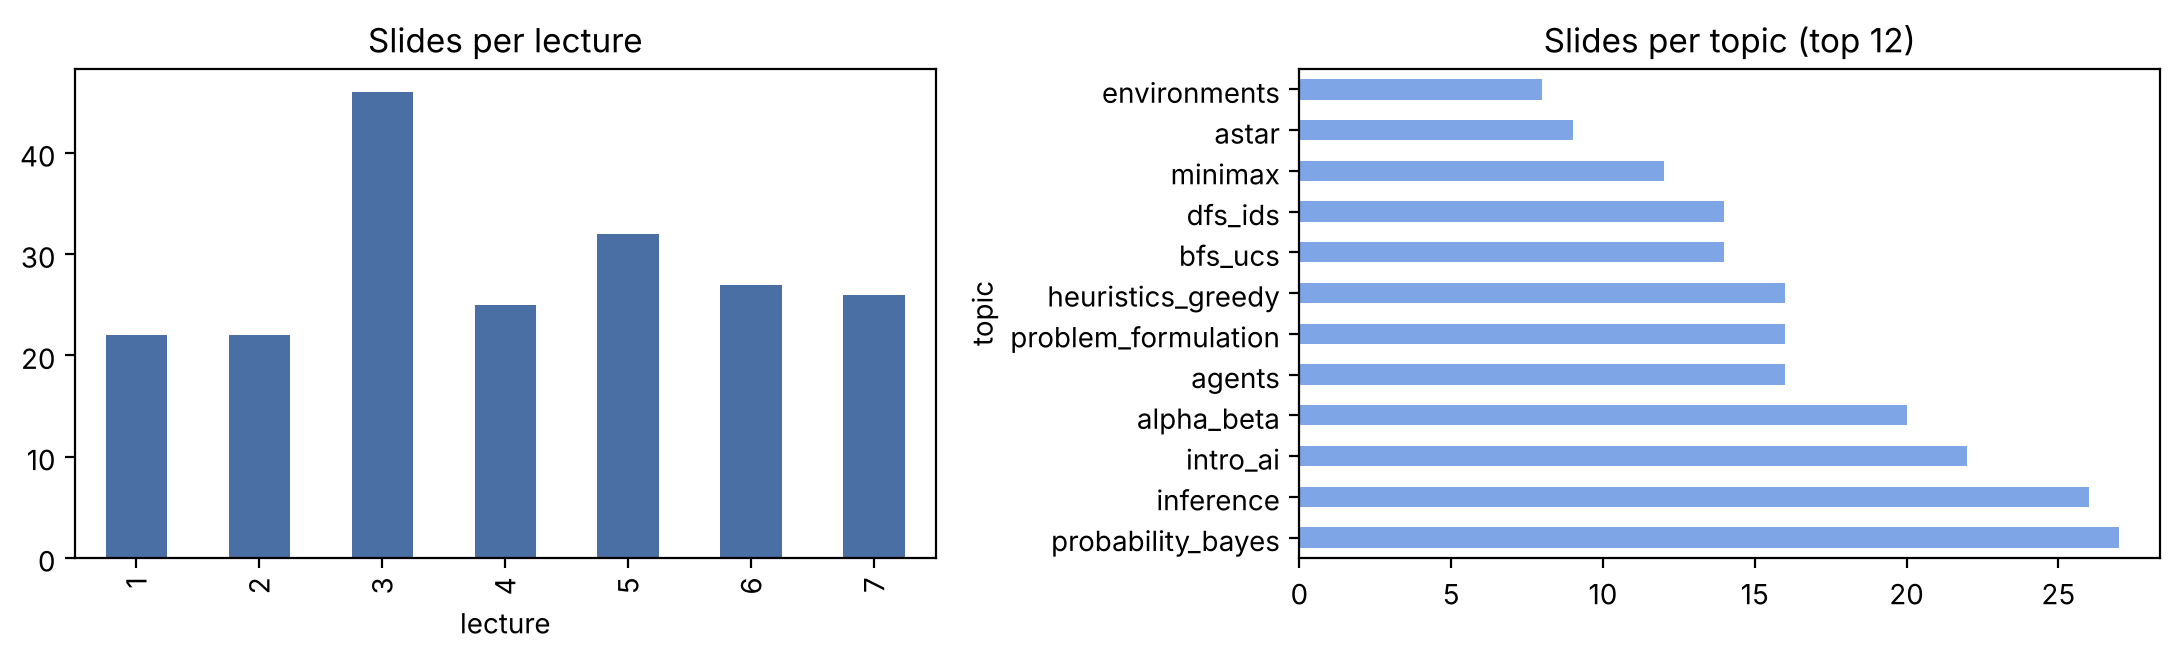

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
passages.groupby("lecture").size().plot.bar(ax=ax[0], color="#4a6fa5", title="Slides per lecture")
passages["topic"].value_counts().head(12).plot.barh(ax=ax[1], color="#7ea5e6", title="Slides per topic (top 12)")
plt.tight_layout(); plt.savefig("results/data_overview.png", dpi=130); plt.show()

## 3 · Train the search index & evaluate the 4 methods (hold-out)
**Protocol (same as the site):** from every slide with ≥3 sentences one sentence is removed and used as a question; the index is trained **without** those sentences.
*Top-1* = the source slide is ranked first, *Top-3* = in the first three, *MRR* = mean reciprocal rank.
**Off-topic test:** sentences from the *other* courses must be refused ("Not found").

In [6]:
res = autoeval.run(COURSE, n_queries=150, seed=0)
rows = [{"Method": v["name"], "Top-1 %": v["top1"]*100, "Top-3 %": v["top3"]*100, "MRR": v["mrr"]} for v in res["methods"].values()]
table = pd.DataFrame(rows).set_index("Method").round(1)
print(f"Course {res['course']} · {res['slides']} slides · {res['n_queries']} test questions · {res['when']}")
print(f"Off-topic questions refused: {res['offtopic']['rejected']}/{res['offtopic']['total']}")
table

Course AI · 200 slides · 85 test questions · 2026-11-12 01:50
Off-topic questions refused: 30/40


,Top-1 %,Top-3 %,MRR
Method,,,
TF-IDF,27.1,45.9,0.4
BM25,27.1,45.9,0.4
Hybrid (TF-IDF + semantic),24.7,49.4,0.4
Semantic (LSA),23.5,48.2,0.4


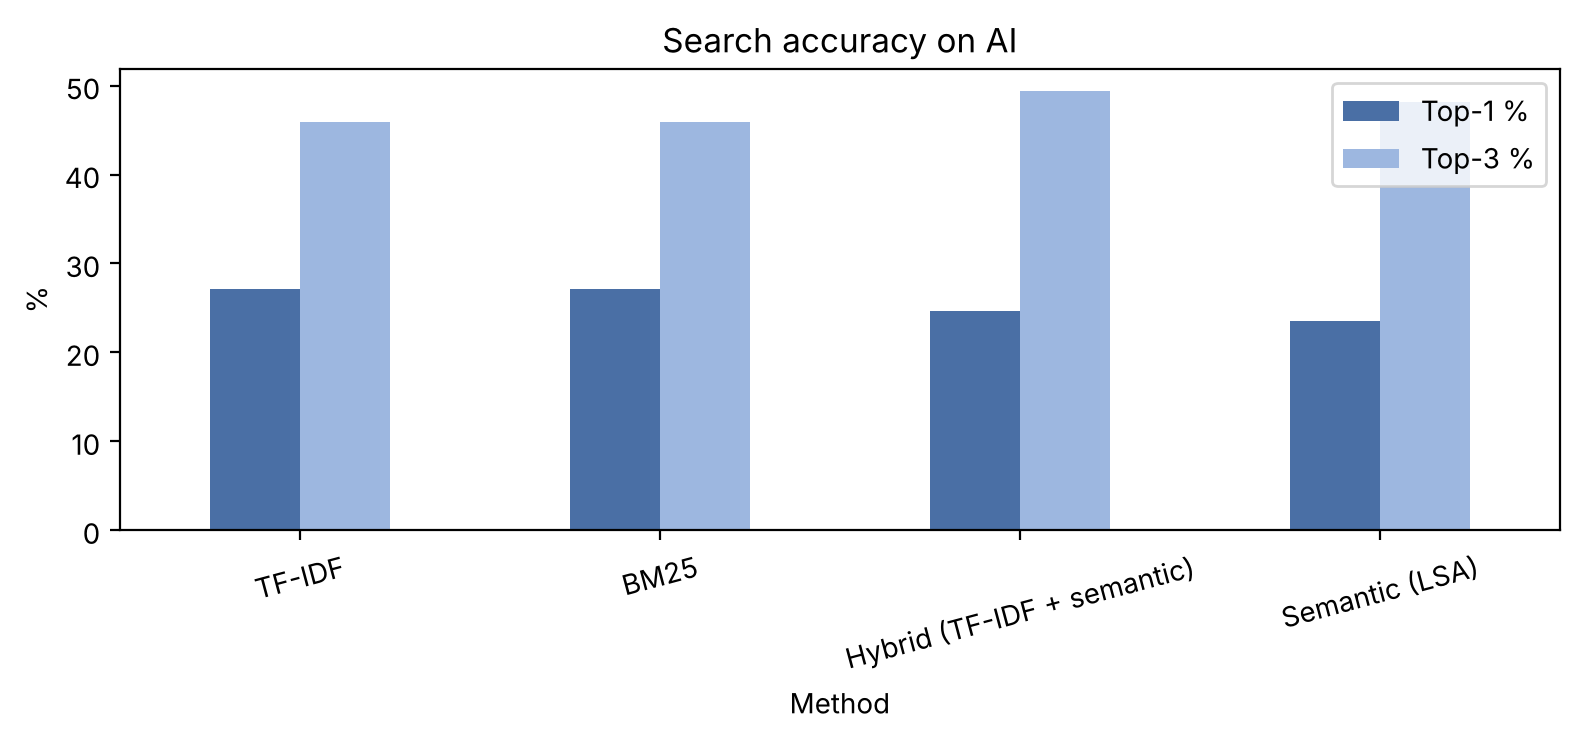

In [7]:
ax = table[["Top-1 %", "Top-3 %"]].plot.bar(figsize=(8, 3.8), color=["#4a6fa5", "#9db7e0"], rot=15, title=f"Search accuracy on {COURSE}")
ax.set_ylabel("%"); plt.tight_layout(); plt.savefig("results/search_accuracy.png", dpi=130); plt.show()
table.to_csv("results/search_accuracy.csv"); json.dump(res, open("results/auto_metrics.json", "w"), indent=1, ensure_ascii=False)

## 4 · The percentages change with the course
Run the evaluation on every course in the repo: more / different slides ⇒ different numbers. This is exactly what the site recomputes after each upload.

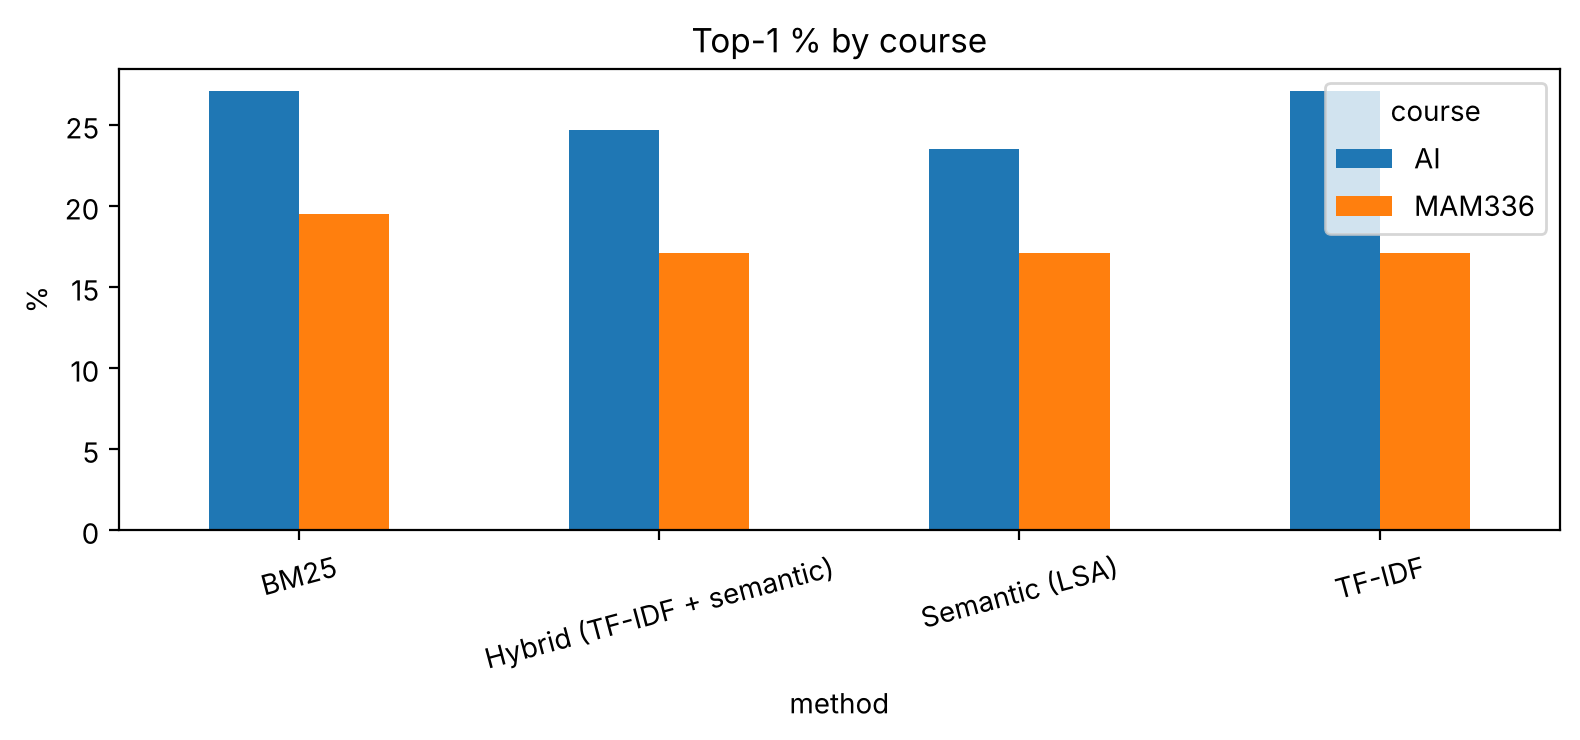

,course,slides,method,Top-1 %,Top-3 %
0,AI,200,TF-IDF,27.1,45.9
1,AI,200,BM25,27.1,45.9
2,AI,200,Hybrid (TF-IDF + semantic),24.7,49.4
3,AI,200,Semantic (LSA),23.5,48.2
4,MAM336,108,TF-IDF,17.1,30.5
5,MAM336,108,BM25,19.5,36.6
6,MAM336,108,Hybrid (TF-IDF + semantic),17.1,31.7
7,MAM336,108,Semantic (LSA),17.1,31.7


In [8]:
rows = []
for c in config.list_courses():
    r = autoeval.run(c["code"], n_queries=150, seed=0)
    if not r: continue
    for k, v in r["methods"].items():
        rows.append({"course": c["code"], "slides": r["slides"], "method": v["name"], "Top-1 %": round(v["top1"]*100, 1), "Top-3 %": round(v["top3"]*100, 1)})
cmp = pd.DataFrame(rows)
piv = cmp.pivot(index="method", columns="course", values="Top-1 %")
piv.plot.bar(figsize=(8, 3.8), rot=15, title="Top-1 % by course"); plt.ylabel("%"); plt.tight_layout()
plt.savefig("results/courses_comparison.png", dpi=130); plt.show()
cmp.to_csv("results/courses_comparison.csv", index=False); cmp

## 5 · Try it: one question, four methods

In [9]:
eng = SearchEngine(passages if "topic_name" in passages else passages.assign(topic_name=passages["topic"]))
def demo(q):
    print("Question:", q, "| in course?", eng.is_in_course(q)[0])
    for m in ["tfidf", "bm25", "hybrid", "lsa"]:
        found, hit = eng.search(q, k=1, method=m)
        r = hit[0] if hit else None
        print(f"  {m:7s} ->", (f"lecture {r['lecture']} slide {r['slide']}" if r else "no result"))
demo(passages.text.iloc[10].split(".")[0])
demo("What is the capital of France?")

Question: Act Rationally Rational Agent Approach Perceive the environment, and act so as to achieve one’s goal | in course? True
  tfidf   -> lecture 1 slide 15
  bm25    -> lecture 1 slide 15
  hybrid  -> lecture 1 slide 15
  lsa     -> lecture 1 slide 15
Question: What is the capital of France? | in course? False
  tfidf   -> no result
  bm25    -> no result
  hybrid  -> no result
  lsa     -> no result


## 6 · Train the topic classifier (the model behind "which topic is this question about?")
Slides are labelled with their topic; two models are trained and compared with 5-fold cross-validation, like `models/topic_classifier_*.joblib` in the project.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
d = passages[passages.text.str.len() > 40]
vc = d["topic"].value_counts(); d = d[d["topic"].isin(vc[vc >= 5].index)]
cv = StratifiedKFold(5, shuffle=True, random_state=0)
out = {}
for name, clf in [("Logistic Regression", LogisticRegression(max_iter=2000, C=5)), ("Naive Bayes", MultinomialNB(alpha=0.3))]:
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, stop_words="english"), clf)
    s = cross_val_score(pipe, d.text, d.topic, cv=cv)
    out[name] = round(s.mean()*100, 1)
    print(f"{name:20s} accuracy {s.mean()*100:5.1f}%  (±{s.std()*100:.1f})  on {len(d)} slides, {d.topic.nunique()} topics")
json.dump(out, open("results/topic_classifier.json", "w"))

Logistic Regression  accuracy  74.0%  (±2.5)  on 200 slides, 12 topics
Naive Bayes          accuracy  75.0%  (±2.2)  on 200 slides, 12 topics


## 7 · Save & download the output for the TA

In [11]:
print(sorted(os.listdir("results")))
try:
    from google.colab import files
    shutil.make_archive("studymate_search_results", "zip", "results"); files.download("studymate_search_results.zip")
except ImportError:
    print("Results are in ./results")

['auto_metrics.json', 'courses_comparison.csv', 'courses_comparison.png', 'data_overview.png', 'search_accuracy.csv', 'search_accuracy.png', 'topic_classifier.json']
Results are in ./results


### Notes
* Metrics are *hold-out* retrieval metrics on the course's own slides, not a human-labelled test; the repo also has hand-made `search_test.csv` and `offtopic_test.csv` for the AI course.
* TF-IDF and BM25 are lexical; LSA/Hybrid add semantic matching. The site lets the student pick the method and explains the difference on the *Help* page.
* Everything runs on CPU in a few seconds — the same models run on the free PythonAnywhere plan.